# Weekly demand forecasting: walkthrough

Same pipeline as `src/`, with the series and error tables shown. Run `run_all.sh` first.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

panel = pd.read_parquet('../data/weekly.parquet')
products = pd.read_csv('../results/products.csv', dtype={'sku': str})
print(f"{panel['week'].nunique()} weeks, {panel['sku'].nunique() - 1} products + TOTAL")
products.head(8)

104 weeks, 20 products + TOTAL


,sku,weeks,revenue,description
0,85123A,102,237765.80,WHITE HANGING HEART T-LIGHT HOLDER
1,85099B,102,163891.39,JUMBO BAG RED RETROSPOT
2,47566,101,139638.17,PARTY BUNTING
3,84879,102,118865.75,ASSORTED COLOUR BIRD ORNAMENT
4,79321,95,82134.04,CHILLI LIGHTS
5,22197,102,71750.01,SMALL POPCORN HOLDER
6,22386,96,69086.91,JUMBO BAG PINK POLKADOT
7,85099F,101,64183.72,JUMBO BAG STRAWBERRY


## 1. The series

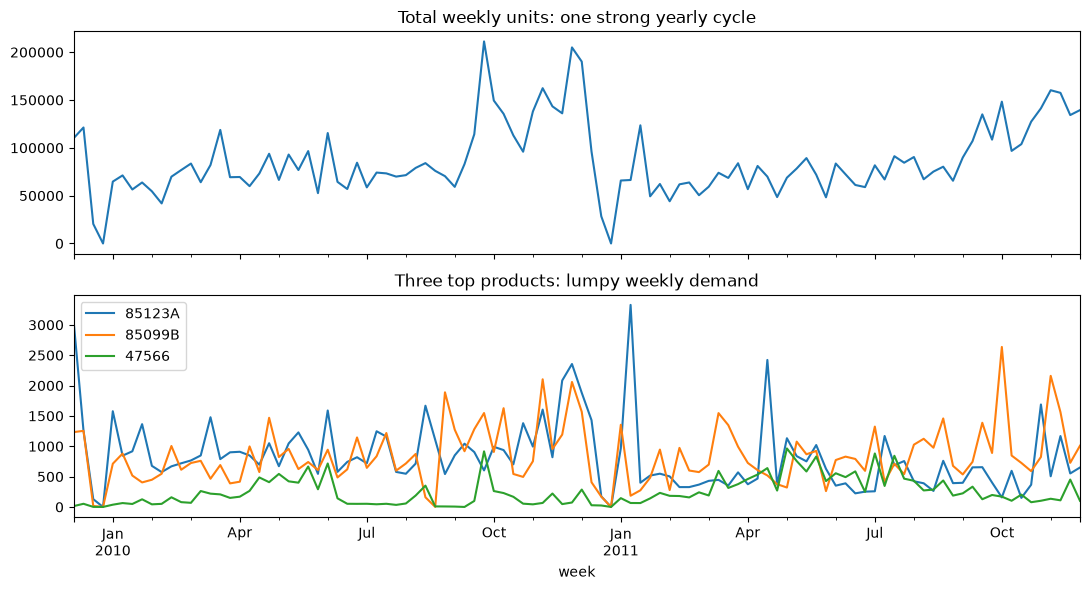

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
tot = panel[panel['sku'] == 'TOTAL'].set_index('week')['units']
tot.plot(ax=axes[0], title='Total weekly units: one strong yearly cycle')
for sku in products['sku'].head(3):
    panel[panel['sku'] == sku].set_index('week')['units'].plot(ax=axes[1], label=sku)
axes[1].set_title('Three top products: lumpy weekly demand'); axes[1].legend()
plt.tight_layout(); plt.show()

## 2. Holdout errors

In [3]:
m = json.load(open('../results/metrics.json'))
print(m['setup'])
pd.DataFrame(m['methods']).T

{'products': 20, 'weeks': 104, 'holdout_weeks': 12, 'holdout_start': '2011-09-12', 'holdout_end': '2011-11-28', 'lags': [1, 2, 3, 4, 8, 52]}


,products_wape_pooled,products_wape_median,products_mae,total_wape,total_mae
naive,0.589,0.683,231.1,0.165,21435.0
seasonal_naive,0.668,0.867,262.2,0.202,26232.0
holt_damped,0.446,0.499,175.1,0.167,21655.0
gradient_boost,0.522,0.534,204.9,0.196,25447.0


In [4]:
errors = pd.read_csv('../results/errors_by_product.csv', dtype={'sku': str})
errors.sort_values('gradient_boost')

,sku,naive,seasonal_naive,holt_damped,gradient_boost
20,TOTAL,0.164939,0.201851,0.166632,0.195809
15,84879,0.302910,0.955383,0.221502,0.275542
1,20725,0.347961,0.374402,0.304796,0.316853
9,22197,0.477123,0.403999,0.417010,0.448985
7,22112,0.434114,0.360870,0.433930,0.462609
0,20685,0.645425,0.727124,0.687908,0.468483
19,85123A,0.761109,1.188487,0.439112,0.468795
6,21931,0.480600,0.448854,0.278326,0.468866
11,22411,0.495000,0.441111,0.468821,0.501758
10,22386,0.517252,0.545199,0.475192,0.522036


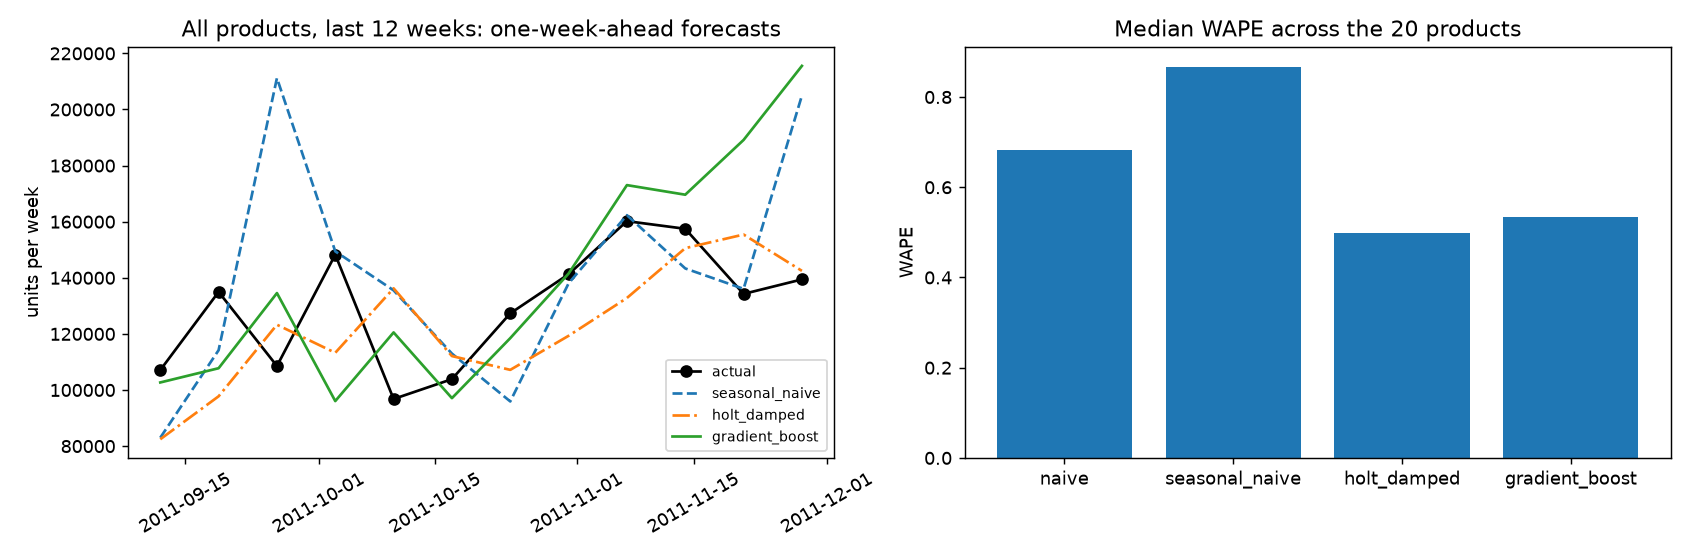

In [5]:
display(Image('../results/forecasts.png', width=1000))

## 3. One product, all four methods

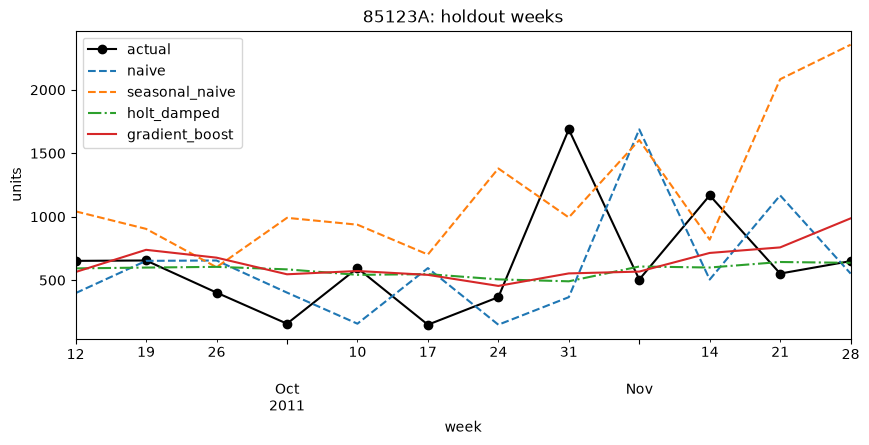

In [6]:
fc = pd.read_csv('../results/forecasts.csv', dtype={'sku': str}, parse_dates=['week'])
sku = products['sku'].iloc[0]
g = fc[fc['sku'] == sku].set_index('week')
g[['actual', 'naive', 'seasonal_naive', 'holt_damped', 'gradient_boost']].plot(figsize=(10, 4), style=['k-o', '--', '--', '-.', '-'], title=f'{sku}: holdout weeks')
plt.ylabel('units'); plt.show()

Seasonal naive is a strong baseline here because the yearly cycle dominates; the boosting model adds the most on the aggregate series. The products with the largest errors are the ones with single-week trade orders, which no history-only method anticipates.